# 03 - Localização da sonda

**Pergunta:** a partir só da imagem da câmera, onde a sonda está no mapa?

**Métodos comparados:**
- **ORB + homografia**: keypoints binários, casamento por Hamming, teste de razão de Lowe e RANSAC.
- **SIFT + homografia**: o mesmo pipeline com descritores SIFT, mais caros e mais robustos.
- **Template matching** (Lab08, *baseline*): procura o frame inteiro no mapa por correlação normalizada. Recebe o zoom verdadeiro, como se viesse de um altímetro, mas não trata rotação.
- **ORB sem equalização** (ablação): o ORB acima equaliza o histograma do mapa e do frame antes de extrair features. Esta versão tira a equalização para medir quanto ela ajuda.

**Protocolo:** 300 frames simulados (`simulador.amostra_aleatoria`, semente fixa). Cada um tem posição, rumo (0–360°) e zoom (0,6–1,6) aleatórios, além de degradações aleatórias (ruído, blur, brilho e gama). A posição real é conhecida.

**Métricas:**
- Erro de posição em km (mediana e p90).
- Taxa de sucesso: localizou e o erro ficou abaixo de 1 km.
- Erro de rumo.
- Tempo por frame.

In [1]:
import sys
sys.path.insert(0, "..")

import time

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from pouso_lunar import config
from pouso_lunar.dados import carregar_mapa
from pouso_lunar.localizador import Localizador, localizar_template
from pouso_lunar.metricas import erro_km
from pouso_lunar.simulador import amostra_aleatoria, gerar_frame, posicao_aleatoria

config.PASTA_RESULTADOS.mkdir(exist_ok=True)
mapa, info = carregar_mapa()
L = mapa.shape[1]
t0 = time.perf_counter()
orb = Localizador(mapa, "orb", cache=config.PASTA_DADOS / f"cache_orb_{L}.npz")
sift = Localizador(mapa, "sift", cache=config.PASTA_DADOS / f"cache_sift_{L}.npz")
orb_sem_eq = Localizador(mapa, "orb", equalizar=False)
print(f"keypoints no mapa: ORB {len(orb.pts)}, SIFT {len(sift.pts)}, ORB sem equalização {len(orb_sem_eq.pts)} "
      f"({time.perf_counter() - t0:.1f} s)")

N = 300
amostra = amostra_aleatoria(mapa, N, config.SEMENTE)

# Tipo de terreno: brilho médio do frame LIMPO (sem as degradações aleatórias de
# brilho/gama). Usar o frame degradado mediria o brilho sorteado, não o terreno.
def brilho_limpo(v):
    return gerar_frame(mapa, v.x, v.y, v.rumo_graus, v.zoom)[0].mean()
brilho = {id(v): brilho_limpo(v) for _, v in amostra}
mediana_terreno = np.median(list(brilho.values()))

def dif_angular(a, b):
    return abs((a - b + 180) % 360 - 180)

METODOS = {
    "ORB": lambda f, v: orb.localizar(f),
    "SIFT": lambda f, v: sift.localizar(f),
    "Template": lambda f, v: localizar_template(mapa, f, v.zoom),
    "ORB sem equalização": lambda f, v: orb_sem_eq.localizar(f),
}

def avaliar(frames, metodos=METODOS):
    linhas = []
    for nome, fn in metodos.items():
        for i, (f, v) in enumerate(frames):
            t = time.perf_counter()
            r = fn(f, v)
            ms = 1000 * (time.perf_counter() - t)
            e = erro_km(r.x, r.y, v.x, v.y, info.km_por_px) if r.ok else np.nan
            linhas.append({
                "metodo": nome, "frame": i, "ok": r.ok, "erro_km": e,
                "sucesso": bool(r.ok and e < 1.0),
                "erro_rumo": dif_angular(r.rumo_graus, v.rumo_graus) if r.ok else np.nan,
                "inliers": r.n_inliers, "tempo_ms": ms,
                "terreno": ("mar" if brilho[id(v)] < mediana_terreno else "terras altas") if id(v) in brilho else "-",
            })
    return pd.DataFrame(linhas)

res = avaliar(amostra)

keypoints no mapa: ORB 30000, SIFT 70620, ORB sem equalização 28311 (2.6 s)


## Resumo

In [2]:
resumo = res.groupby("metodo", sort=False).agg(
    taxa_sucesso=("sucesso", "mean"),
    erro_mediano_km=("erro_km", "median"),
    erro_p90_km=("erro_km", lambda s: s.quantile(0.9)),
    erro_rumo_mediano_graus=("erro_rumo", "median"),
    tempo_medio_ms=("tempo_ms", "mean"),
)
resumo.to_csv(config.PASTA_RESULTADOS / "localizacao_metricas.csv")
resumo.round(3)

,taxa_sucesso,erro_mediano_km,erro_p90_km,erro_rumo_mediano_graus,tempo_medio_ms
metodo,,,,,
ORB,0.747,0.183,0.474,1.055,167.651
SIFT,0.753,0.114,0.216,0.251,1205.124
Template,0.013,24.660,360.257,24.929,188.609
ORB sem equalização,0.383,0.157,0.360,0.623,34.633


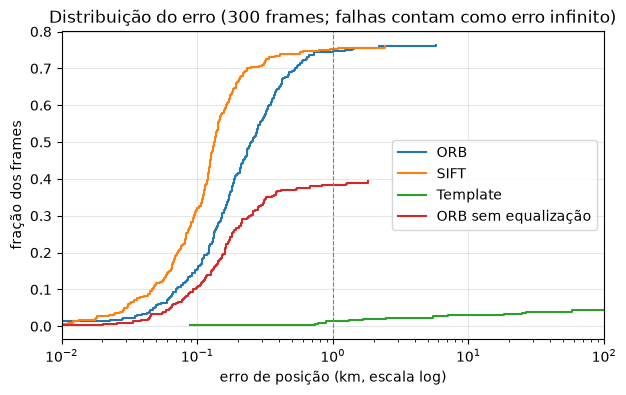

In [3]:
fig, ax = plt.subplots(figsize=(7, 4))
for nome, g in res.groupby("metodo", sort=False):
    e = np.sort(g["erro_km"].fillna(np.inf).to_numpy())
    ax.step(e, np.arange(1, len(e) + 1) / len(e), where="post", label=nome)
ax.axvline(1.0, color="gray", ls="--", lw=0.8)
ax.set_xscale("log"); ax.set_xlim(0.01, 100)
ax.set_xlabel("erro de posição (km, escala log)"); ax.set_ylabel("fração dos frames")
ax.set_title(f"Distribuição do erro ({N} frames; falhas contam como erro infinito)")
ax.legend(); ax.grid(alpha=0.3)
fig.savefig(config.PASTA_RESULTADOS / "localizacao_erro_cdf.png", dpi=110, bbox_inches="tight")
plt.show()

## Robustez: um fator por vez

Mesmas 30 posições. Variamos **um** fator de cada vez e deixamos os outros neutros: rumo 0°, zoom 1 e sem degradação.

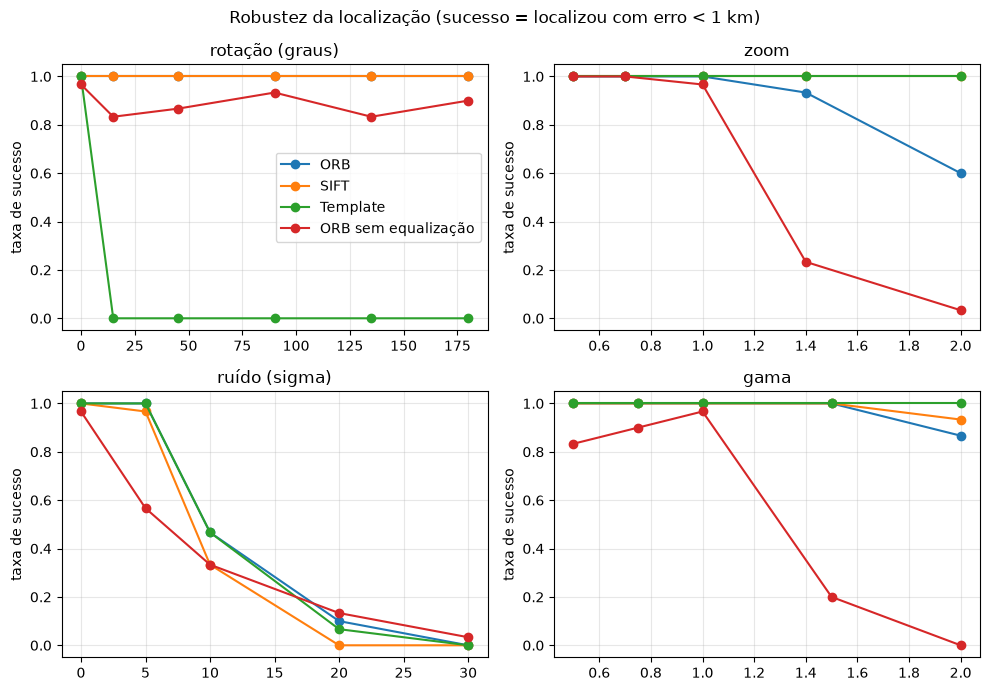

In [4]:
rng = np.random.default_rng(config.SEMENTE + 1)
posicoes = [posicao_aleatoria(rng, 0.5, config.TAM_FRAME, L, L) for _ in range(30)]
fatores = {
    "rotação (graus)": ("rumo_graus", [0, 15, 45, 90, 135, 180]),
    "zoom": ("zoom", [0.5, 0.7, 1.0, 1.4, 2.0]),
    "ruído (sigma)": ("ruido_sigma", [0, 5, 10, 20, 30]),
    "gama": ("gama", [0.5, 0.75, 1.0, 1.5, 2.0]),
}
rob = []
for titulo, (chave, valores) in fatores.items():
    for val in valores:
        kw = {"rumo_graus": 0.0, "zoom": 1.0, chave: val}
        rumo, zoom = kw.pop("rumo_graus"), kw.pop("zoom")
        frames = [gerar_frame(mapa, x, y, rumo, zoom, rng=np.random.default_rng(i), **kw)
                  for i, (x, y) in enumerate(posicoes)]
        r = avaliar(frames)
        for nome, g in r.groupby("metodo", sort=False):
            rob.append({"fator": titulo, "valor": val, "metodo": nome, "taxa_sucesso": g["sucesso"].mean()})
rob = pd.DataFrame(rob)
rob.to_csv(config.PASTA_RESULTADOS / "localizacao_robustez.csv", index=False)

fig, axs = plt.subplots(2, 2, figsize=(10, 7))
for ax, (titulo, g) in zip(axs.ravel(), rob.groupby("fator", sort=False)):
    for nome, gm in g.groupby("metodo", sort=False):
        ax.plot(gm["valor"], gm["taxa_sucesso"], "o-", label=nome)
    ax.set_title(titulo); ax.set_ylim(-0.05, 1.05); ax.grid(alpha=0.3)
    ax.set_ylabel("taxa de sucesso")
axs[0, 0].legend()
fig.suptitle("Robustez da localização (sucesso = localizou com erro < 1 km)")
fig.tight_layout()
fig.savefig(config.PASTA_RESULTADOS / "localizacao_robustez.png", dpi=110, bbox_inches="tight")
plt.show()

## Um exemplo: o que o ORB está casando

À esquerda, o frame da câmera (girado e degradado). À direita, a região do mapa. As linhas ligam os **inliers** do RANSAC, isto é, as correspondências que concordam com uma mesma homografia.

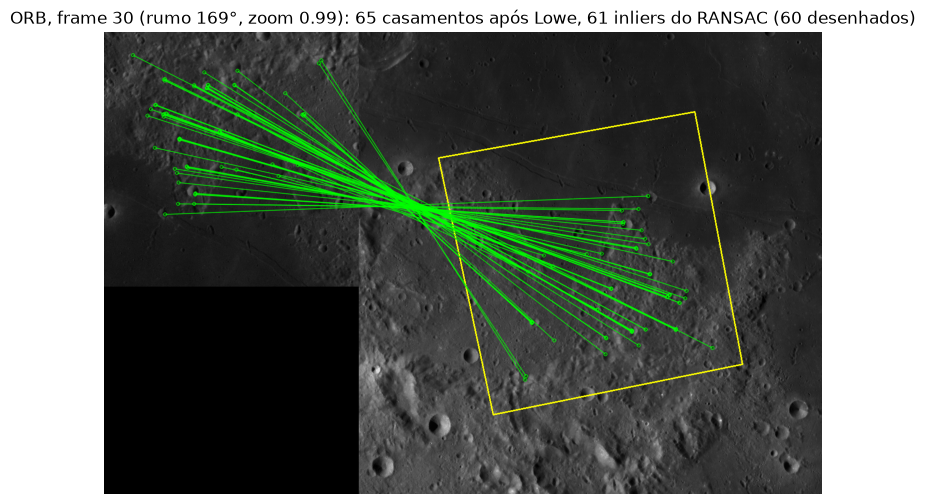

In [5]:
# exemplo representativo: entre os frames em que o ORB deu certo, o de nº de inliers mais próximo da mediana
ok = res[(res.metodo == "ORB") & res.sucesso]
idx = int(ok.iloc[(ok.inliers - ok.inliers.median()).abs().argmin()].frame)
f, v = amostra[idx]
kf, df = orb.det_frame.detectAndCompute(orb._prep(f), None)
bons = [m[0] for m in orb.matcher.knnMatch(df, orb.desc, k=2)
        if len(m) == 2 and m[0].distance < config.RAZAO_LOWE * m[1].distance]
src = np.float32([kf[m.queryIdx].pt for m in bons]).reshape(-1, 1, 2)
dst = orb.pts[[m.trainIdx for m in bons]].reshape(-1, 1, 2)
H, mask = cv2.findHomography(src, dst, cv2.RANSAC, config.LIMIAR_RANSAC_PX)
inl = mask.ravel().astype(bool)
c = config.TAM_FRAME - 1
quad = cv2.perspectiveTransform(np.float32([[[0, 0], [c, 0], [c, c], [0, c]]]), H)[0]
x0, y0 = np.maximum(quad.min(0) - 150, 0).astype(int)
x1, y1 = np.minimum(quad.max(0) + 150, L).astype(int)
recorte = cv2.cvtColor(mapa[y0:y1, x0:x1], cv2.COLOR_GRAY2BGR)
cv2.polylines(recorte, [(quad - [x0, y0]).astype(np.int32)], True, (0, 255, 255), 2)
kp_m = [cv2.KeyPoint(float(p[0][0] - x0), float(p[0][1] - y0), 5) for p in dst[inl]]
kp_f = [cv2.KeyPoint(float(p[0][0]), float(p[0][1]), 5) for p in src[inl]]
pares = [cv2.DMatch(i, i, 0) for i in range(len(kp_f))]
vis = cv2.drawMatches(cv2.cvtColor(f, cv2.COLOR_GRAY2BGR), kp_f, recorte, kp_m, pares[:60], None,
                      matchColor=(0, 255, 0), flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
plt.figure(figsize=(12, 6)); plt.imshow(vis[..., ::-1]); plt.axis("off")
plt.title(f"ORB, frame {idx} (rumo {v.rumo_graus:.0f}°, zoom {v.zoom:.2f}): "
          f"{len(bons)} casamentos após Lowe, {inl.sum()} inliers do RANSAC (60 desenhados)")
plt.savefig(config.PASTA_RESULTADOS / "localizacao_exemplo.png", dpi=110, bbox_inches="tight")
plt.show()

## Mar × terras altas

O mar é liso e tem poucas crateras, ou seja, pouca textura. A hipótese é que ali os detectores de features encontram menos pontos e falham mais.

O terreno de cada frame é classificado pelo brilho médio do frame **limpo**, antes das degradações. O mar é escuro e as terras altas são claras.

In [6]:
terreno = res.groupby(["metodo", "terreno"], sort=False)["sucesso"].mean().unstack()
terreno.to_csv(config.PASTA_RESULTADOS / "localizacao_terreno.csv")
terreno.round(3)

terreno,terras altas,mar
metodo,,
ORB,0.787,0.707
SIFT,0.827,0.680
Template,0.013,0.013
ORB sem equalização,0.653,0.113
